# Stream A — Visual Grounding (Updated)

**Key change:** NC entity caches now use composite keys `{id}_{int(falsified)}`.
NC VG is now real — uses metadata entities + pre-extracted CLIP image embeddings.

**Order:** `ner_pipeline` → **`visual_grounding`** → `entity_scorer`

## 1. Setup

In [10]:
import sys, pickle, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch, open_clip
from PIL import Image
from tqdm import tqdm

sys.path.insert(0, str(Path('../../').resolve()))
from src.utils.paths import *
from src.utils.io import load_json

sns.set_theme(style='whitegrid', font_scale=1.1)
C_OOC='#E05A4B'; C_GENUINE='#4B8AE0'

VG_CACHE     = CACHE / 'visual_grounding'
NER_CACHE    = CACHE / 'ner'
PAPER_FIGS   = ROOT  / 'paper' / 'figures'
PAPER_TABLES = ROOT  / 'paper' / 'tables'
for d in [VG_CACHE, PAPER_FIGS, PAPER_TABLES]: d.mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

def savefig(name):
    p = PAPER_FIGS / f'{name}.png'
    plt.savefig(p, bbox_inches='tight', dpi=150)
    print(f'  Saved -> {p.relative_to(ROOT)}')

def savecsv(df, name):
    p = PAPER_TABLES / f'{name}.csv'
    df.to_csv(p, index=False)
    print(f'  Saved -> {p.relative_to(ROOT)}')

Device: cuda


## 2. Load NER caches

In [11]:
verite_ner = pickle.load(open(NER_CACHE/'entities_verite.pkl','rb'))
mmfake_ner = pickle.load(open(NER_CACHE/'entities_mmfake.pkl','rb'))
nc_ner = {split: pickle.load(open(NER_CACHE/f'entities_newsclippings_{split}.pkl','rb'))
          for split in ['train','val','test']}

# Validate composite keys in NC
for split, d in nc_ner.items():
    sample = next(iter(d)) if d else ''
    has_composite = '_' in sample
    n_with = sum(1 for v in d.values() if v)
    print(f'  NC/{split}: {len(d):,} entries | composite_keys={has_composite} | with_entities={n_with:,}')

print(f'  VERITE: {len(verite_ner):,} | MMFake: {len(mmfake_ner):,}')

  NC/train: 71,072 entries | composite_keys=True | with_entities=71,068
  NC/val: 7,024 entries | composite_keys=True | with_entities=7,022
  NC/test: 7,264 entries | composite_keys=True | with_entities=7,264
  VERITE: 1,001 | MMFake: 10,000


## 3. Load CLIP model

In [12]:
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai')
clip_tokenizer = open_clip.get_tokenizer('ViT-B-32')
clip_model = clip_model.to(DEVICE).eval()

def encode_texts(texts, batch_size=512):
    vecs = []
    for i in range(0, len(texts), batch_size):
        toks = clip_tokenizer(texts[i:i+batch_size]).to(DEVICE)
        with torch.no_grad(), torch.amp.autocast('cuda', enabled=(DEVICE=='cuda')):
            v = clip_model.encode_text(toks).float()
            v = v / v.norm(dim=-1, keepdim=True)
        vecs.append(v.cpu().numpy())
    return np.concatenate(vecs, axis=0) if vecs else np.zeros((0,512))

def encode_images_from_paths(paths, batch_size=64):
    vecs = []
    for i in range(0, len(paths), batch_size):
        batch = []
        for p in paths[i:i+batch_size]:
            try: img = clip_preprocess(Image.open(p).convert('RGB'))
            except: img = torch.zeros(3,224,224)
            batch.append(img)
        imgs = torch.stack(batch).to(DEVICE)
        with torch.no_grad(), torch.amp.autocast('cuda', enabled=(DEVICE=='cuda')):
            v = clip_model.encode_image(imgs).float()
            v = v / v.norm(dim=-1, keepdim=True)
        vecs.append(v.cpu().numpy())
        torch.cuda.empty_cache()
    return np.concatenate(vecs, axis=0) if vecs else np.zeros((0,512))

# Smoke test
with torch.no_grad():
    f = clip_model.encode_text(clip_tokenizer(['test']).to(DEVICE))
print(f'  CLIP loaded. Text embedding shape: {f.shape}')

C:\Users\User\AppData\Roaming\Python\Python313\site-packages\open_clip\factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


  CLIP loaded. Text embedding shape: torch.Size([1, 512])


## 4. NewsCLIPpings VG — pre-extracted embeddings + metadata entities

Now real scores because NER cache has actual entities from metadata.

In [13]:
def newsclip_vg_split(split, ner_split_dict):
    out_path = VG_CACHE / f'vg_newsclippings_{split}.pkl'

    # Check for valid (non-empty) cache with composite keys
    if out_path.exists():
        existing = pickle.load(open(out_path,'rb'))
        sample_key = next(iter(existing)) if existing else ''
        n_with = sum(1 for v in existing.values() if v)
        if '_' in sample_key and n_with > 0:
            print(f'  NC/{split}: loaded from cache ({len(existing):,} entries, {n_with:,} with scores)')
            return existing
        print(f'  NC/{split}: rebuilding cache (old format or empty scores)...')

    # Load pre-extracted CLIP image embeddings
    img_emb_path = CLIP_EMB / 'clip_image_embeddings' / f'{split}.pkl'
    if not img_emb_path.exists():
        print(f'  WARNING: {img_emb_path} not found')
        res = {k: {} for k in ner_split_dict}
        pickle.dump(res, open(out_path,'wb'), protocol=4)
        return res

    img_embs = pickle.load(open(img_emb_path,'rb'))  # {image_id: np.array}

    # Load pair JSON for id -> image_id mapping
    raw = load_json(NEWSCLIP / f'{split}.json')
    pairs = raw.get('annotations', raw) if isinstance(raw, dict) else raw
    # composite_key -> image_id
    key_to_imgid = {f'{str(row["id"])}_{int(row["falsified"])}': row['image_id']
                for row in pairs}

    # Encode all unique entity prompts in one batch
    unique_prompts = set()
    for ents in ner_split_dict.values():
        for e in ents:
            unique_prompts.add(f'a photo of {e["text"]}')

    if not unique_prompts:
        print(f'  NC/{split}: no entities in NER cache -- run ner_pipeline first')
        res = {k: {} for k in ner_split_dict}
        pickle.dump(res, open(out_path,'wb'), protocol=4)
        return res

    print(f'  NC/{split}: encoding {len(unique_prompts):,} entity prompts...')
    prompt_list = list(unique_prompts)
    prompt_vecs = encode_texts(prompt_list)
    prompt_idx  = {p: i for i, p in enumerate(prompt_list)}

    print(f'  NC/{split}: computing grounding for {len(ner_split_dict):,} pairs...')
    t0 = time.time()
    res = {}
    missing_img = 0
    for key, ents in tqdm(ner_split_dict.items(), desc=f'VG NC/{split}'):
        imgid = key_to_imgid.get(key)
        if not ents or imgid not in img_embs:
            if imgid not in img_embs and ents: missing_img += 1
            res[key] = {}
            continue
        img_v = img_embs[imgid].astype(np.float32)
        img_v = img_v / (np.linalg.norm(img_v) + 1e-8)
        scores = {}
        for e in ents:
            prompt = f'a photo of {e["text"]}'
            txt_v  = prompt_vecs[prompt_idx[prompt]]
            scores[e['text']] = float(np.dot(img_v, txt_v))
        res[key] = scores

    pickle.dump(res, open(out_path,'wb'), protocol=4)
    n_with = sum(1 for v in res.values() if v)
    print(f'  NC/{split}: {len(res):,} entries | {n_with:,} with scores | {time.time()-t0:.1f}s')
    if missing_img: print(f'    {missing_img} pairs had entities but no image embedding')
    return res

nc_vg = {split: newsclip_vg_split(split, nc_ner[split])
         for split in ['train','val','test']}

  NC/train: encoding 41,654 entity prompts...
  NC/train: computing grounding for 71,072 pairs...


VG NC/train: 100%|██████████| 71072/71072 [00:01<00:00, 49135.77it/s]


  NC/train: 71,072 entries | 71,068 with scores | 1.5s
  NC/val: encoding 6,163 entity prompts...
  NC/val: computing grounding for 7,024 pairs...


VG NC/val: 100%|██████████| 7024/7024 [00:00<00:00, 48949.01it/s]

  NC/val: 7,024 entries | 7,022 with scores | 0.2s


  NC/test: encoding 6,315 entity prompts...
  NC/test: computing grounding for 7,264 pairs...


VG NC/test: 100%|██████████| 7264/7264 [00:00<00:00, 48328.93it/s]

  NC/test: 7,264 entries | 7,264 with scores | 0.2s


## 5. VERITE VG

In [14]:
def dataset_vg_from_images(ner_dict, image_paths, cache_path, desc='VG'):
    if cache_path.exists():
        res = pickle.load(open(cache_path,'rb'))
        print(f'  {desc}: loaded from cache ({len(res):,} entries)')
        return res
    unique_prompts = set()
    for ents in ner_dict.values():
        for e in ents: unique_prompts.add(f'a photo of {e["text"]}')
    if not unique_prompts:
        res = {k: {} for k in ner_dict}
        pickle.dump(res, open(cache_path,'wb'), protocol=4)
        return res
    prompt_list = list(unique_prompts)
    prompt_vecs = encode_texts(prompt_list)
    prompt_idx  = {p: i for i, p in enumerate(prompt_list)}
    pids  = list(image_paths.keys())
    paths = [image_paths[p] for p in pids]
    img_vecs = encode_images_from_paths(paths)
    pid_to_vec = {pid: img_vecs[i] for i, pid in enumerate(pids)}
    res = {}
    for pid, ents in tqdm(ner_dict.items(), desc=desc):
        if not ents or pid not in pid_to_vec: res[pid] = {}; continue
        img_v = pid_to_vec[pid]
        res[pid] = {e['text']: float(np.dot(img_v, prompt_vecs[prompt_idx[f'a photo of {e["text"]}']]))
                    for e in ents}
    pickle.dump(res, open(cache_path,'wb'), protocol=4)
    print(f'  {desc}: {len(res):,} entries saved -> {cache_path.name}')
    return res

verite_csv = pd.read_csv(VERITE / 'VERITE.csv')
verite_img_paths = {f'verite_{i}': VERITE/'images'/f'{row["image_path"].split("/")[-1]}'
                    for i, (_,row) in enumerate(verite_csv.iterrows())}
# Fallback: try direct false_N.jpg / true_N.jpg naming
def verite_img_path(i, row):
    for candidate in [
        VERITE / 'images' / row.get('image_path','').split('/')[-1],
        VERITE / 'images' / f'false_{i}.jpg',
        VERITE / 'images' / f'true_{i}.jpg',
    ]:
        if Path(candidate).exists(): return Path(candidate)
    return Path(VERITE / 'images' / row.get('image_path','').split('/')[-1])

verite_img_paths = {f'verite_{i}': verite_img_path(i, row)
                    for i, row in verite_csv.iterrows()}
missing_v = sum(1 for p in verite_img_paths.values() if not p.exists())
print(f'  VERITE images: {len(verite_img_paths):,} | missing: {missing_v}')

verite_vg = dataset_vg_from_images(verite_ner, verite_img_paths,
                                    VG_CACHE/'vg_verite.pkl', desc='VG VERITE')

  VERITE images: 1,001 | missing: 958
  VG VERITE: loaded from cache (1,001 entries)


## 6. MMFakeBench VG

In [15]:
raw = load_json(DATA/'mmfakebench'/'MMFakeBench_test.json')
mm_pairs_list = raw if isinstance(raw, list) else list(raw.values())
MM_IMG_ROOT = DATA / 'mmfakebench' / 'MMFakeBench_test'
mmfake_img_paths = {f'mmfake_{i}': MM_IMG_ROOT / row.get('image_path','').lstrip('/')
                    for i, row in enumerate(mm_pairs_list)}
missing_m = sum(1 for p in mmfake_img_paths.values() if not p.exists())
print(f'  MMFake images: {len(mmfake_img_paths):,} | missing: {missing_m}')

mmfake_vg = dataset_vg_from_images(mmfake_ner, mmfake_img_paths,
                                    VG_CACHE/'vg_mmfake.pkl', desc='VG MMFake')

  MMFake images: 10,000 | missing: 0
  VG MMFake: loaded from cache (10,000 entries)


## 7. Merge + stats

In [16]:
vg_all = {}
for split in ['train','val','test']: vg_all.update(nc_vg[split])
vg_all.update(verite_vg)
vg_all.update(mmfake_vg)
pickle.dump(vg_all, open(VG_CACHE/'vg_all.pkl','wb'), protocol=4)

n_with = sum(1 for v in vg_all.values() if v)
print(f'  Merged: {len(vg_all):,} entries | {n_with:,} with scores')
for name, d in [('NC train', nc_vg['train']),('NC val',nc_vg['val']),('NC test',nc_vg['test']),
                ('VERITE', verite_vg), ('MMFake', mmfake_vg)]:
    nw = sum(1 for v in d.values() if v)
    print(f'    {name:<12}: {len(d):,} total | {nw:,} with scores ({nw/max(len(d),1)*100:.1f}%)')

  Merged: 96,361 entries | 93,118 with scores
    NC train    : 71,072 total | 71,068 with scores (100.0%)
    NC val      : 7,024 total | 7,022 with scores (100.0%)
    NC test     : 7,264 total | 7,264 with scores (100.0%)
    VERITE      : 1,001 total | 928 with scores (92.7%)
    MMFake      : 10,000 total | 6,836 with scores (68.4%)


## 8. OOC vs Genuine scores

  OOC     mean=0.258  median=0.256  n=9,115
  Genuine mean=0.266  median=0.266  n=5,913
  Saved -> paper\figures\vg_score_ooc_vs_genuine.png


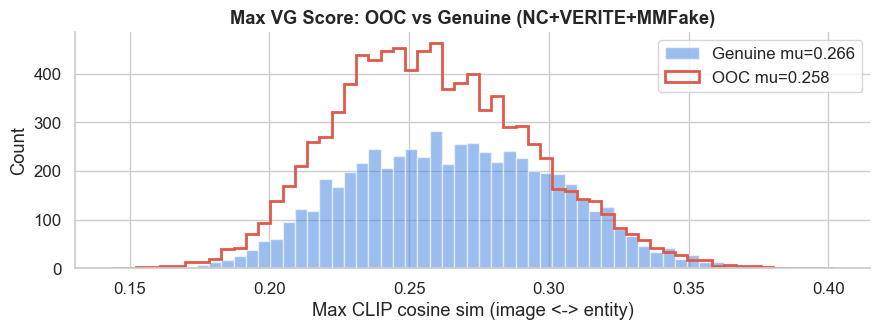

  Saved -> paper\tables\vg_stats.csv
  Saved -> paper\tables\vg_per_sample_scores.csv


In [17]:
def bin_label(v):
    return 1 if str(v).strip().lower() in ('1','true','out-of-context') else 0

verite_df = pd.read_csv(VERITE/'VERITE.csv')
verite_df['label'] = verite_df['label'].apply(bin_label)
raw = load_json(DATA/'mmfakebench'/'MMFakeBench_test.json')
mm_list = raw if isinstance(raw, list) else list(raw.values())
mmfake_df = pd.DataFrame(mm_list)
mmfake_df['label'] = (mmfake_df['gt_answers'].str.lower()=='fake').astype(int)

ooc_scores, gen_scores, rows = [], [], []

# NC test
raw_nc = load_json(NEWSCLIP/'test.json')
nc_test_pairs = raw_nc.get('annotations', raw_nc) if isinstance(raw_nc, dict) else raw_nc
for row in nc_test_pairs:
    key = f'{row["id"]}_{int(row["falsified"])}'
    scores = nc_vg['test'].get(key,{})
    max_s = max(scores.values()) if scores else np.nan
    lbl = int(row['falsified'])
    rows.append({'source':'nc','label':lbl,'max_vg_score':max_s})
    if not np.isnan(max_s): (ooc_scores if lbl==1 else gen_scores).append(max_s)

# VERITE + MMFake
for df_src, vg_dict, src in [(verite_df, verite_vg, 'verite'),
                              (mmfake_df, mmfake_vg, 'mmfake')]:
    for i, row in df_src.iterrows():
        pid = f'{src}_{i}'
        scores = vg_dict.get(pid,{})
        max_s  = max(scores.values()) if scores else np.nan
        lbl    = int(row['label'])
        rows.append({'source':src,'label':lbl,'max_vg_score':max_s})
        if not np.isnan(max_s): (ooc_scores if lbl==1 else gen_scores).append(max_s)

ooc_arr = np.array(ooc_scores); gen_arr = np.array(gen_scores)
print(f'  OOC     mean={ooc_arr.mean():.3f}  median={np.median(ooc_arr):.3f}  n={len(ooc_arr):,}')
print(f'  Genuine mean={gen_arr.mean():.3f}  median={np.median(gen_arr):.3f}  n={len(gen_arr):,}')

fig, ax = plt.subplots(figsize=(9,3.5))
lo=min(ooc_arr.min(),gen_arr.min()); hi=max(ooc_arr.max(),gen_arr.max())
bins=np.linspace(lo,hi,60)
ax.hist(gen_arr, bins=bins, alpha=0.55, color='#4B8AE0', label=f'Genuine mu={gen_arr.mean():.3f}')
ax.hist(ooc_arr, bins=bins, histtype='step', linewidth=2.0, color='#E05A4B', label=f'OOC mu={ooc_arr.mean():.3f}')
ax.set_title('Max VG Score: OOC vs Genuine (NC+VERITE+MMFake)', fontweight='bold')
ax.set_xlabel('Max CLIP cosine sim (image <-> entity)')
ax.set_ylabel('Count'); ax.legend()
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); savefig('vg_score_ooc_vs_genuine'); plt.show()

vg_stats = pd.DataFrame({'class':['genuine','ooc'],
    'mean':[round(gen_arr.mean(),4),round(ooc_arr.mean(),4)],
    'median':[round(float(np.median(gen_arr)),4),round(float(np.median(ooc_arr)),4)],
    'n':[len(gen_arr),len(ooc_arr)]})
savecsv(vg_stats, 'vg_stats')
savecsv(pd.DataFrame(rows), 'vg_per_sample_scores')

## 9. Done

In [18]:
print('='*55)
print('  Visual grounding complete (updated).')
print('='*55)
for f in sorted(VG_CACHE.glob('*.pkl')):
    print(f'  {f.name:<45} {f.stat().st_size/1e6:.1f} MB')
print()
print('  Next: notebooks/02_stream_a/entity_scorer.ipynb')

  Visual grounding complete (updated).
  vg_all.pkl                                    6.4 MB
  vg_mmfake.pkl                                 0.5 MB
  vg_newsclippings_test.pkl                     0.5 MB
  vg_newsclippings_train.pkl                    4.8 MB
  vg_newsclippings_val.pkl                      0.5 MB
  vg_verite.pkl                                 0.1 MB

  Next: notebooks/02_stream_a/entity_scorer.ipynb
